In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ipynb.fs.full.preprocessing as pp

In [2]:
def read_the_data(scan: str, path: str): 
    data = pd.read_csv(f"../../../DeltabotController/python/{path}/scan_{scan}/data.csv")
    return (data)

def relative_cx_cy(data, start_cx, start_cy): 
    data["cx_rel"] = data["cx"] - start_cx
    data["cy_rel"] = data["cy"] - start_cy

def px_to_mm(data, x_conversion, y_conversion): 
    data["cx_mm"] = data["cx_rel"]*x_conversion
    data["cy_mm"] = data["cy_rel"]*y_conversion

def process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy):
    data = read_the_data(scan, path)
    relative_cx_cy(data, start_cx, start_cy)   
    px_to_mm(data, x_conversion, y_conversion)
    return data

def combine_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy):
    """creates one dataframe of all the scans"""
    df_list = []
    for scan in scans:
        data = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
        # if scan[1]:
        #     data["cx_mm"] = -data["cx_mm"]
        df_list.append(data)
    combined_data = pd.concat(df_list,ignore_index=True)
    return combined_data

def list_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy):
    all_data = []
    for scan in scans:
        data = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
        all_data.append(data)
        print(all_data)
    return all_data

def dict_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy):
    """creates a dictionary of scan_name: data (df)"""
    all_data = {}
    for scan in scans:
        data = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
        all_data[f"{scan}"] = data
    return all_data

In [3]:
#Specific to these scans
path = "scans/data"
scans = []
for x in [7]: scans.append(f"000{x}_mesh")
for x in range(8,10): scans.append(f"000{x}_dmesh")
for x in range(10,17): scans.append(f"00{x}_dmesh")
for x in range(17,19): scans.append(f"00{x}_mesh")
print(scans)

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 382 #px
start_cy = 270 #px

['0007_mesh', '0008_dmesh', '0009_dmesh', '0010_dmesh', '0011_dmesh', '0012_dmesh', '0013_dmesh', '0014_dmesh', '0015_dmesh', '0016_dmesh', '0017_mesh', '0018_mesh']


In [4]:
print(scans)
data_concat = combine_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy)
print(data_concat.last_valid_index())
print(len(data_concat.dropna()))
display(data_concat.tail(10))

['0007_mesh', '0008_dmesh', '0009_dmesh', '0010_dmesh', '0011_dmesh', '0012_dmesh', '0013_dmesh', '0014_dmesh', '0015_dmesh', '0016_dmesh', '0017_mesh', '0018_mesh']
4475
4121


,point,time,x,y,x_rb,y_rb,s0,s1,s2,strain,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
4466,615,1128.0063,0.3,2.2,0.299952,2.2,11264,-6962,-4302,0.0,...,232.0,6.0,240.0,92.0,520.0,372.0,-2.0,-38.0,-0.018182,-0.345455
4467,616,1129.7941,0.4,2.2,0.400086,2.2,11264,-7406,-3858,0.0,...,236.0,6.0,232.0,96.0,512.0,376.0,-10.0,-34.0,-0.090909,-0.309091
4468,617,1131.5787,0.5,2.2,0.499994,2.2,11264,-7849,-3415,0.0,...,236.0,6.0,222.0,96.0,502.0,376.0,-20.0,-34.0,-0.181818,-0.309091
4469,618,1133.3667,0.6,2.2,0.599903,2.2,11264,-8292,-2972,0.0,...,240.0,6.0,214.0,100.0,494.0,380.0,-28.0,-30.0,-0.254545,-0.272727
4470,619,1135.1544,0.7,2.2,0.700037,2.2,11264,-8736,-2528,0.0,...,246.0,6.0,202.0,106.0,482.0,386.0,-40.0,-24.0,-0.363636,-0.218182
4471,620,1136.9411,0.8,2.2,0.799946,2.2,11264,-9179,-2085,0.0,...,248.0,6.0,188.0,108.0,468.0,388.0,-54.0,-22.0,-0.490909,-0.200000
4472,621,1138.7287,0.9,2.2,0.900080,2.2,11264,-9623,-1641,0.0,...,248.0,6.0,172.0,108.0,452.0,388.0,-70.0,-22.0,-0.636364,-0.200000
4473,622,1140.5148,1.0,2.2,0.999989,2.2,11264,-10066,-1198,0.0,...,248.0,6.0,156.0,108.0,436.0,388.0,-86.0,-22.0,-0.781818,-0.200000
4474,623,1142.3427,1.1,2.2,1.099897,2.2,11264,-10509,-755,0.0,...,250.0,6.0,140.0,110.0,420.0,390.0,-102.0,-20.0,-0.927273,-0.181818
4475,624,1144.1619,1.2,2.2,1.200032,2.2,11264,-10953,-311,0.0,...,254.0,6.0,126.0,114.0,406.0,394.0,-116.0,-16.0,-1.054545,-0.145455


In [5]:
print(scans)
all_data = dict_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy)

data_amount = []
for scan in scans: 
    data_amount.append((len(all_data[scan]), len(all_data[scan].dropna())))
print(data_amount)

['0007_mesh', '0008_dmesh', '0009_dmesh', '0010_dmesh', '0011_dmesh', '0012_dmesh', '0013_dmesh', '0014_dmesh', '0015_dmesh', '0016_dmesh', '0017_mesh', '0018_mesh']
[(625, 603), (289, 283), (289, 262), (289, 218), (289, 282), (289, 280), (289, 273), (289, 280), (289, 285), (289, 279), (625, 548), (625, 528)]


Text(0.5, 1.0, 'set x and y values')

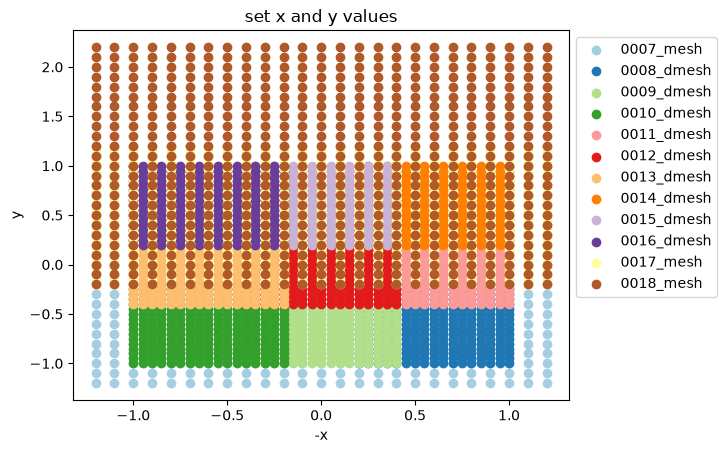

In [6]:
cmap=plt.get_cmap('Paired')
for i, scan in enumerate(scans): 
    plt.scatter(-all_data[scan]["x"], all_data[scan]["y"], label=scan , color=cmap(i))
plt.ylabel("y")
plt.xlabel("-x")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("set x and y values")

Text(0.5, 1.0, 'measured cx and cy values')

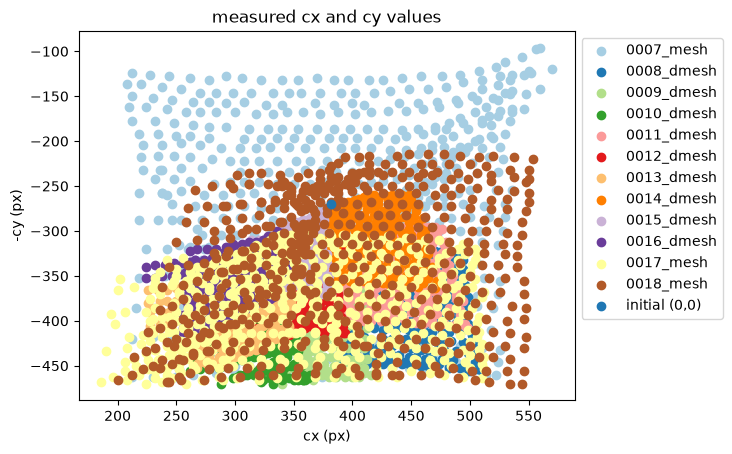

In [7]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx"], -all_data[scan]["cy"], label=scan, color=cmap(i))
plt.ylabel("-cy (px)")
plt.xlabel("cx (px)")
plt.scatter(382, -270, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("measured cx and cy values")

Text(0.5, 1.0, 'converted cx and cy values')

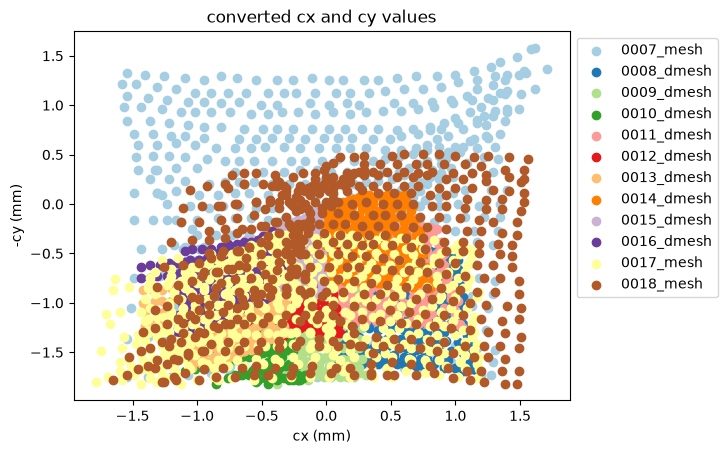

In [8]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx_mm"], -all_data[scan]["cy_mm"], label=scan, color=cmap(i))
plt.ylabel("-cy (mm)")
plt.xlabel("cx (mm)")
# plt.scatter(382*x_conversion, -270*y_conversion, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("converted cx and cy values")

In [9]:
#check didn't track the wrong circle at one point by looking at the radius 
for scan in scans: 
    print(scan, "max: ", max(all_data[scan]["radius"].dropna()), "min: ", min(all_data[scan]["radius"].dropna()))
#all 5 or 6 - good 

0007_mesh max:  6.0 min:  6.0
0008_dmesh max:  6.0 min:  6.0
0009_dmesh max:  6.0 min:  6.0
0010_dmesh max:  6.0 min:  6.0
0011_dmesh max:  6.0 min:  6.0
0012_dmesh max:  6.0 min:  6.0
0013_dmesh max:  6.0 min:  6.0
0014_dmesh max:  6.0 min:  6.0
0015_dmesh max:  6.0 min:  6.0
0016_dmesh max:  6.0 min:  6.0
0017_mesh max:  6.0 min:  5.0
0018_mesh max:  6.0 min:  6.0


<Figure size 640x480 with 0 Axes>

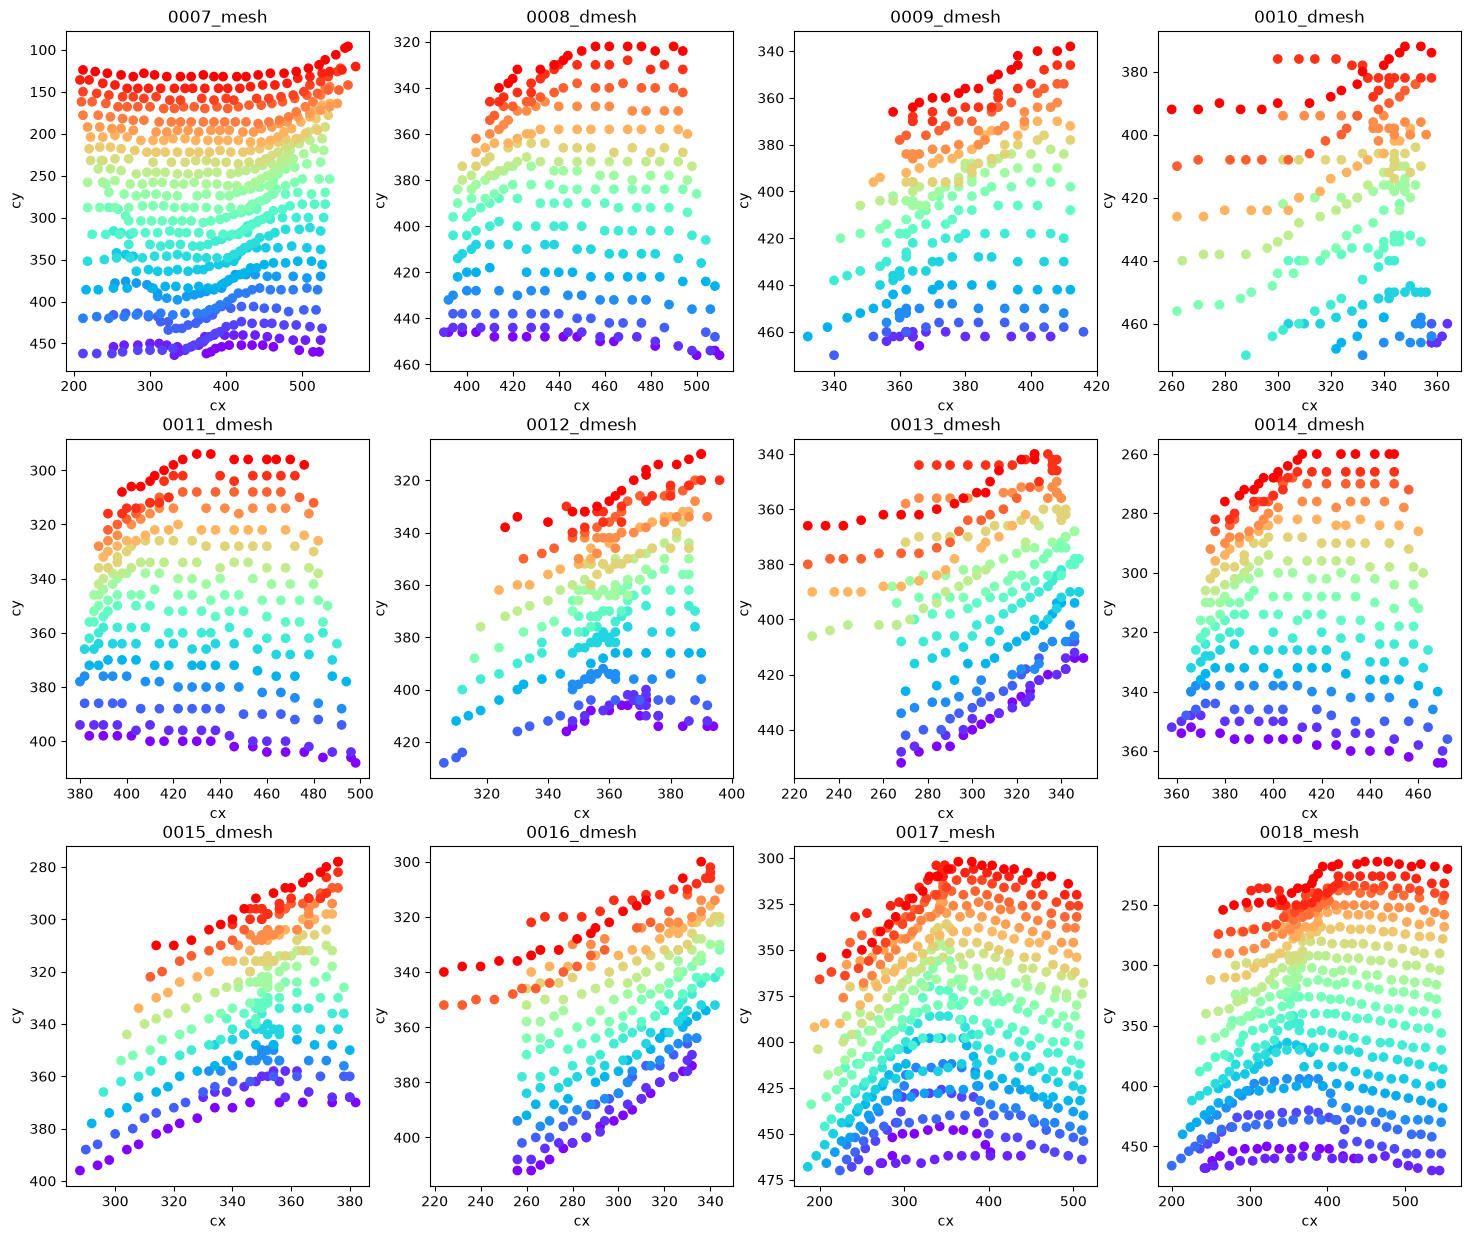

In [10]:
fig = plt.figure()
fig, ax = plt.subplots(3, 4, figsize=(18,15))    

key = 0

for i in range(3):
    for j in range(4):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans[key]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], label=scan, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1

<Figure size 640x480 with 0 Axes>

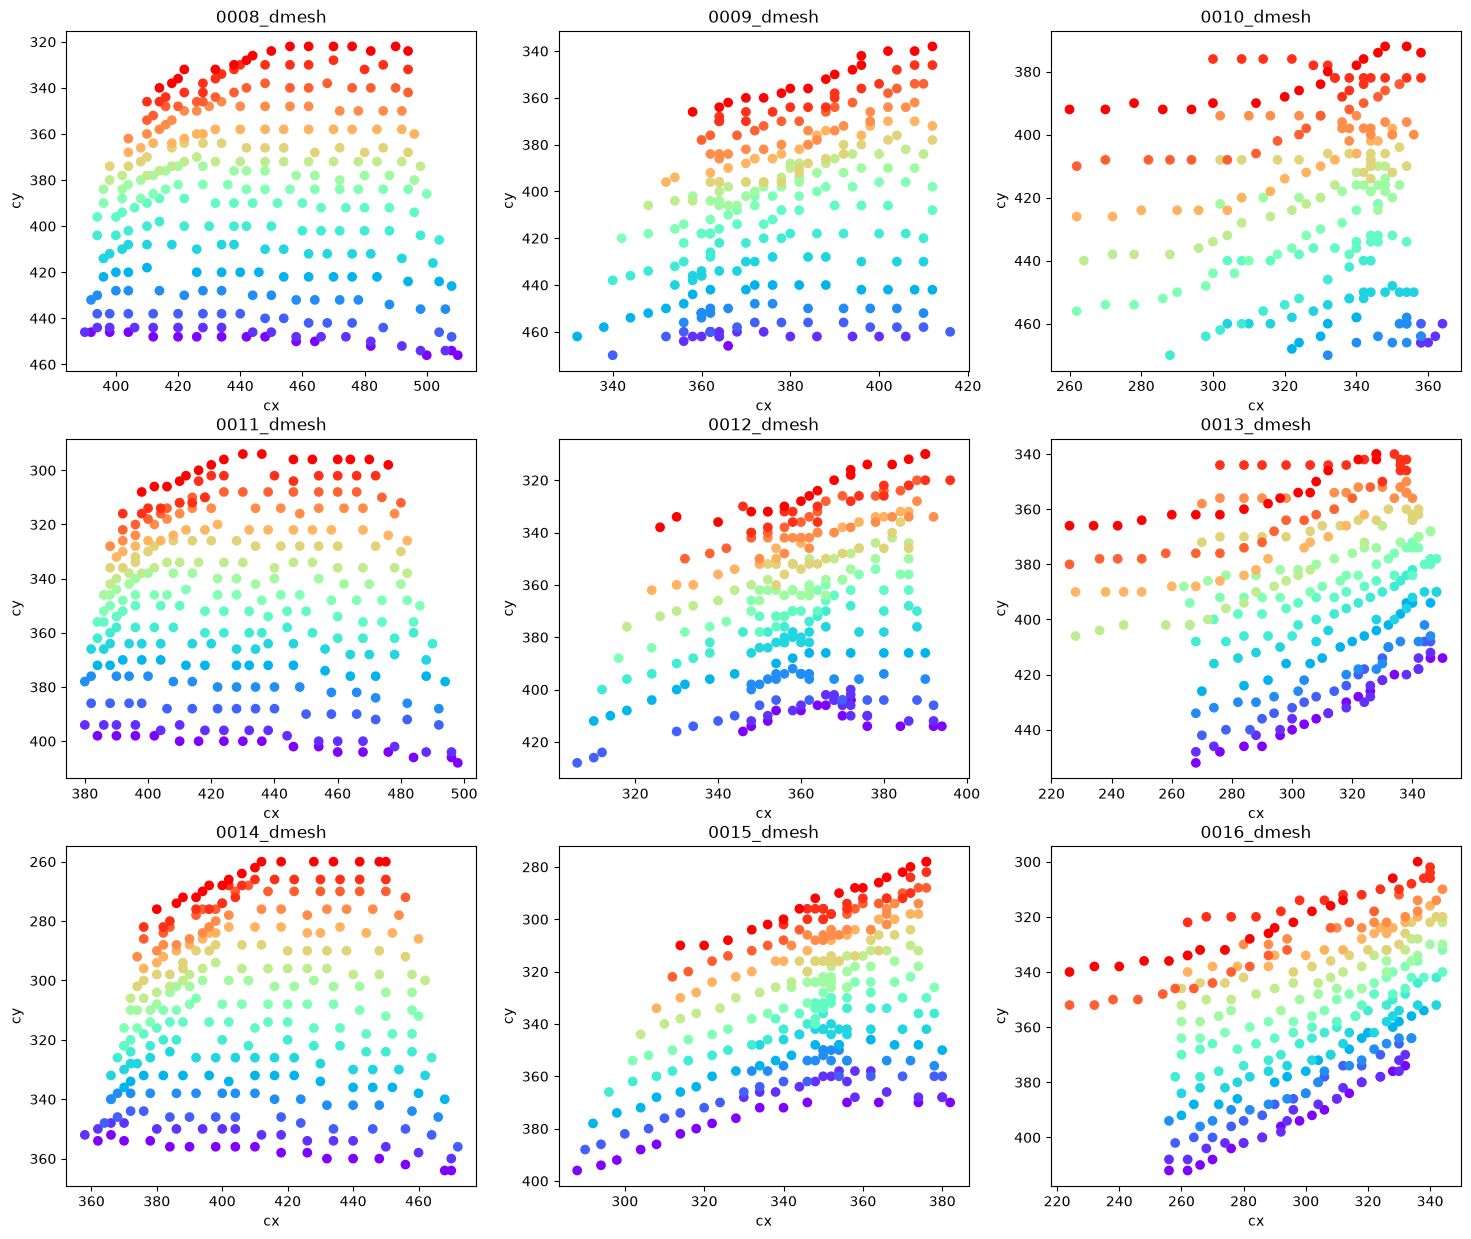

In [11]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(18,15))    

key = 0

scans_to_plot = scans[1:10]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans_to_plot[key]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], label=scan, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1